In [8]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# set up
def find_root(marker: str = "pyproject.toml") -> Path:
    path = Path.cwd().resolve()
    while not (path / marker).exists():
        if path.parent == path:
            raise FileNotFoundError(f"No {marker} found above {Path.cwd()}")
        path = path.parent
    return path

ROOT = find_root()
RAW = ROOT / "data" / "raw" / "vegetation" / "ODK Data Exports"
ENT = ROOT / "data" / "raw" / "vegetation" / "Entity lists"
OUT = ROOT / "data" / "raw" / "output" / "vegetation"


# Read data

In [5]:
EXPECTED = {
    "herbaceous_veg_survey.csv": ["KEY", "ReviewState", "plot_selection-selected_plot_uuid",
                                  "survey_begin-start_time", "survey_end-end_time"],
    "herbaceous_veg_survey-quadrat_repeat.csv": ["KEY", "PARENT_KEY", "quadrat_number", "herbs_present",
                                                 "location_quadrat-Latitude", "location_quadrat-Longitude"],
    "herbaceous_veg_survey-additional_species_repeat.csv": ["KEY", "PARENT_KEY", "species_entry_mode",
                                                            "target_extra_name", "select_reuse_unknown",
                                                            "select_reuse_missing"],
    "register_vegetation_plots.csv": ["KEY", "plot_selection-selected_plot_uuid",
                                      "plot_selection-is_plot_viable"],
}

# first quality check: are all columns in the CSV as expected
def read(folder, name, expected=()):
    df = pd.read_csv(folder / name)
    missing = [c for c in expected if c not in df.columns]
    if missing:
        raise ValueError(f"{name}: missing columns {missing}")
    return df


survey_raw = read(RAW, "herbaceous_veg_survey.csv", EXPECTED["herbaceous_veg_survey.csv"])
quadrat_raw = read(RAW, "herbaceous_veg_survey-quadrat_repeat.csv",
                   EXPECTED["herbaceous_veg_survey-quadrat_repeat.csv"])
addsp_raw = read(RAW, "herbaceous_veg_survey-additional_species_repeat.csv",
                 EXPECTED["herbaceous_veg_survey-additional_species_repeat.csv"])
reg_raw = read(RAW, "register_vegetation_plots.csv", EXPECTED["register_vegetation_plots.csv"])

# these tables won't be updated frequently, so we're not checking the columns
species = read(ENT, "species.csv")
species_extra = read(ENT, "species_extra.csv")
species_ids = read(ENT, "species_extra_ids.csv")
vegplots = read(ENT, "vegplots.csv")
centroids = read(ENT, "centroids.csv")

# print shapes of all exported tables
for name, df in [("surveys", survey_raw), ("quadrats", quadrat_raw), ("additional species", addsp_raw),
                 ("plot registrations", reg_raw)]:
    print(f"{name:20s} {df.shape}")

surveys              (32, 52)
quadrats             (640, 21)
additional species   (1296, 30)
plot registrations   (31, 82)


In [13]:
def xy_m(lat, lon, lat0, lon0):
    """Local equirectangular projection in metres around (lat0, lon0). Accurate to < 0.1 % at plot scale."""
    x = (np.asarray(lon) - lon0) * 111_320 * np.cos(np.radians(lat0))
    y = (np.asarray(lat) - lat0) * 110_574
    return x, y


def dist_m(lat1, lon1, lat2, lon2):
    x, y = xy_m(lat1, lon1, lat2, lon2)
    return np.hypot(x, y)


P = "plot_metadata-collect_points-"

# create new data frame for plots
plots = pd.DataFrame({
    "plot_uuid": reg_raw["plot_selection-selected_plot_uuid"],
    "plot_name": reg_raw["plot_selection-plot_name"],
    "plot_status": reg_raw["plot_selection-sample_status"],
    "is_viable": reg_raw["plot_selection-is_plot_viable"],
    "not_viable_reason": reg_raw["plot_selection-plot_establishment_notes"],
    "ecosystem_type": reg_raw["plot_metadata-ecosystem_type_name"],
    "registered_at": pd.to_datetime(reg_raw["survey_begin-start_time"], utc=True),
})

# GPS columns per transect point, e.g. midpoint_lat, midpoint_lon, midpoint_acc.
COORD_SUFFIX = {"Latitude": "lat", "Longitude": "lon", "Accuracy": "acc"}
for point in ["endpoint_a", "midpoint", "endpoint_b"]:
    for coord, suffix in COORD_SUFFIX.items():
        source_col = f"{P}{point}-location_{point}-{coord}"
        plots[f"{point}_{suffix}"] = reg_raw[source_col]

# vegplots is the entity the survey form selects from. Its __id is what surveys reference.
plots = plots.merge(vegplots[["__id", "plot_uuid"]].rename(columns={"__id": "vegplot_id"}), on="plot_uuid",
                    how="left")

# geometry is a space-separated string that starts with "lat lon".
coords = centroids["geometry"].str.split(expand=True)
cent = centroids[["__id", "stratum_label"]].copy()
cent["centroid_lat"] = coords[0].astype(float)
cent["centroid_lon"] = coords[1].astype(float)

plots = plots.merge(cent, left_on="plot_uuid", right_on="__id", how="left").drop(columns="__id")

plots["midpoint_shift_m"] = dist_m(plots["midpoint_lat"], plots["midpoint_lon"],
                                   plots["centroid_lat"], plots["centroid_lon"])
plots["a_to_mid_m"] = dist_m(plots["endpoint_a_lat"], plots["endpoint_a_lon"], plots["midpoint_lat"], plots["midpoint_lon"])
plots["b_to_mid_m"] = dist_m(plots["endpoint_b_lat"], plots["endpoint_b_lon"], plots["midpoint_lat"], plots["midpoint_lon"])
plots["transect_length_m"] = dist_m(plots["endpoint_a_lat"], plots["endpoint_a_lon"],
                                    plots["endpoint_b_lat"], plots["endpoint_b_lon"])
bx, by = xy_m(plots["endpoint_b_lat"], plots["endpoint_b_lon"], plots["endpoint_a_lat"], plots["endpoint_a_lon"])
plots["bearing_deg"] = np.degrees(np.arctan2(bx, by)) % 180  # 0 = north-south, 90 = east-west
plots["bearing_deviation_deg"] = np.minimum(plots["bearing_deg"], 180 - plots["bearing_deg"])
plots[["plot_name", "plot_status", "is_viable", "midpoint_shift_m", "transect_length_m", "bearing_deg"]].round(1).head()

,plot_name,plot_status,is_viable,midpoint_shift_m,transect_length_m,bearing_deg
0,SavMon_LW_Plot_16,primary,yes,3.5,58.3,100.3
1,SavMon_LW_Plot_11,primary,yes,11.5,42.5,107.8
2,SavMon_LW_Plot_29,primary,yes,8.3,61.9,104.9
3,SavMon_LW_Plot_21,primary,yes,13.8,44.8,97.7
4,SavMon_LW_Plot_18,primary,yes,2.6,45.7,113.5


In [14]:
plots.head()

,plot_uuid,plot_name,plot_status,is_viable,not_viable_reason,ecosystem_type,registered_at,endpoint_a_lat,endpoint_a_lon,endpoint_a_acc,...,vegplot_id,stratum_label,centroid_lat,centroid_lon,midpoint_shift_m,a_to_mid_m,b_to_mid_m,transect_length_m,bearing_deg,bearing_deviation_deg
0,40b5b142-18e5-45da-afa8-4837f520f2cf,SavMon_LW_Plot_16,primary,yes,NaN,Scrub,2026-05-26 14:35:41.501000+00:00,0.219611,37.480986,3.70,...,b1e1fc7f-afbd-404c-bd6c-55b172d722df,savanna,0.219546,37.481244,3.513521,33.134142,25.267031,58.315700,100.311194,79.688806
1,d5645424-6bd7-4ccb-8c86-821984f00e5c,SavMon_LW_Plot_11,primary,yes,NaN,Scrub,2026-05-26 13:14:00.606000+00:00,0.222389,37.466365,4.65,...,e3135c68-679c-4b44-a083-5dc111683665,savanna,0.222328,37.466554,11.516563,27.237764,20.938171,42.495805,107.786717,72.213283
2,5fc30b9c-edc3-410d-8eb9-e9eceb8526dc,SavMon_LW_Plot_29,primary,yes,NaN,Scrub,2026-05-26 09:06:08.301000+00:00,0.226720,37.460463,4.80,...,153ee0a8-8628-4891-8c66-a5d8286552f8,savanna,0.226638,37.460777,8.282993,30.495211,32.432648,61.856345,104.853055,75.146945
3,da09c7a5-a9ba-49c8-9e74-7d262e6b7eb4,SavMon_LW_Plot_21,primary,yes,NaN,Scrub,2026-05-26 07:19:08.278000+00:00,0.225578,37.456683,3.50,...,8070570d-64ca-405a-802d-4d721fdc2fe9,savanna,0.225559,37.456964,13.794754,18.437234,27.555877,44.843863,97.708725,82.291275
4,477053f7-b110-411b-abe4-5b6aadf57ab0,SavMon_LW_Plot_18,primary,yes,NaN,Scrub,2026-05-25 14:31:23.295000+00:00,0.222631,37.438949,3.30,...,a5b642c6-e8ba-4186-a1d3-5ff99852e8b0,savanna,0.222514,37.439133,2.583077,25.017481,20.757796,45.701757,113.498718,66.501282


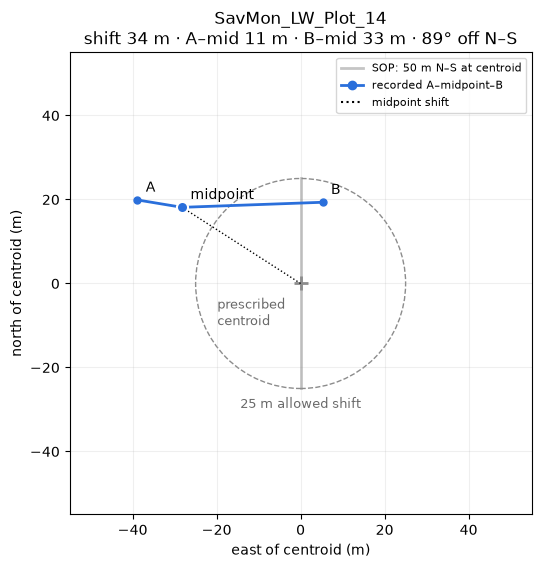

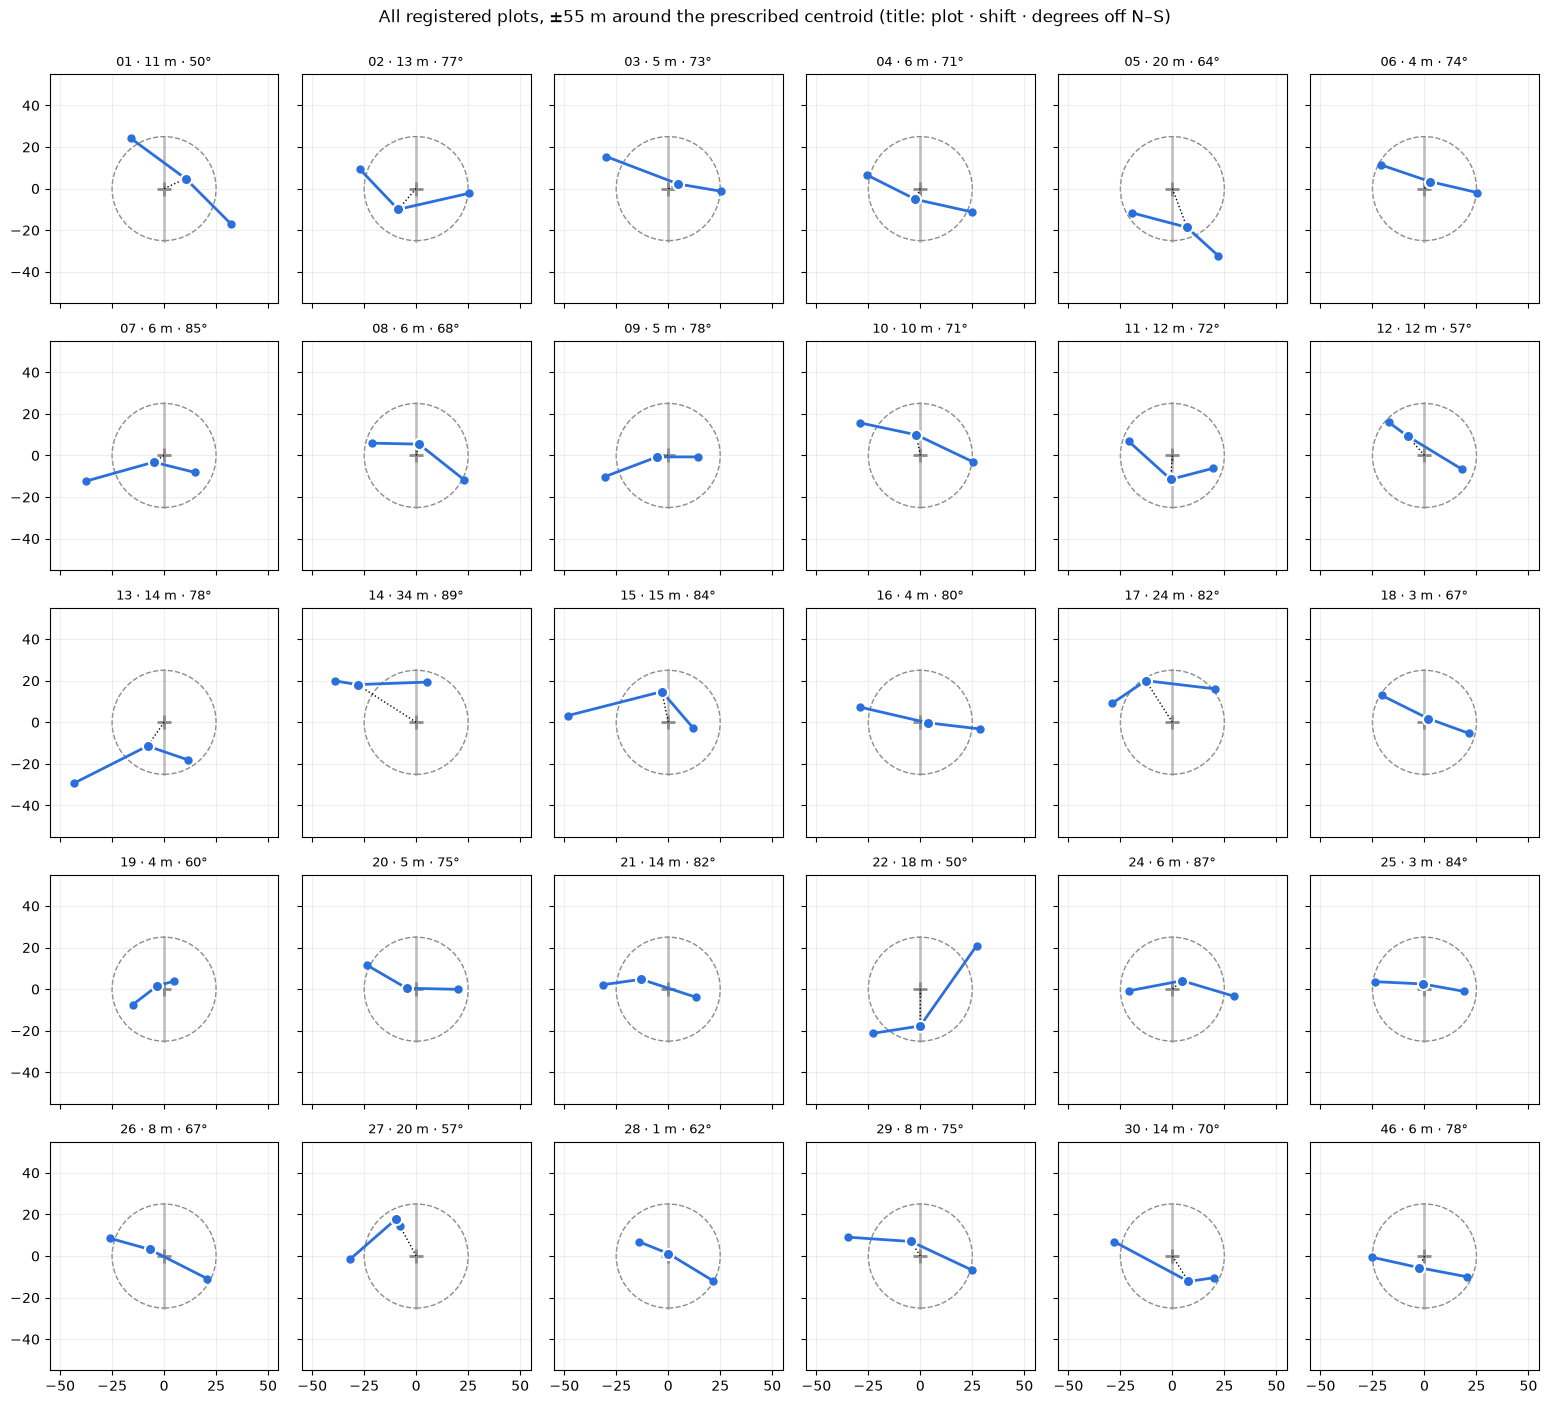

In [15]:
# Each plot in local metres around its prescribed centroid: where the team was sent (grey) and the
# transect they recorded (blue). Same scale in every panel so shifts and rotations are comparable.
TRANSECT_C, PRESCRIBED_C = "#2a6fdb", "#8c8c8c"
MAX_MIDPOINT_SHIFT_M = 25  # SOP: midpoint may move at most 25 m from the prescribed point
HALF_LENGTH_M = 25  # midpoint to endpoint

def xy_m(lat, lon, lat0, lon0):
    """Local equirectangular projection in metres around (lat0, lon0). Accurate to < 0.1 % at plot scale."""
    x = (np.asarray(lon) - lon0) * 111_320 * np.cos(np.radians(lat0))
    y = (np.asarray(lat) - lat0) * 110_574
    return x, y

def draw_plot(ax, r, annotate=False):
    pts = {p: xy_m(r[f"{p}_lat"], r[f"{p}_lon"], r["centroid_lat"], r["centroid_lon"])
           for p in ["endpoint_a", "midpoint", "endpoint_b"]}
    ax.add_patch(plt.Circle((0, 0), MAX_MIDPOINT_SHIFT_M, fill=False, ls="--", lw=1, color=PRESCRIBED_C))
    ax.plot([0, 0], [-HALF_LENGTH_M, HALF_LENGTH_M], color=PRESCRIBED_C, lw=2, alpha=0.5)  # SOP transect
    ax.plot(0, 0, "+", color=PRESCRIBED_C, ms=10, mew=2)
    (ax_, ay), (mx, my), (bx_, by_) = pts["endpoint_a"], pts["midpoint"], pts["endpoint_b"]
    ax.plot([0, mx], [0, my], ":", color="black", lw=1)  # midpoint shift
    ax.plot([ax_, mx, bx_], [ay, my, by_], "-o", color=TRANSECT_C, lw=2, ms=5)
    ax.plot(mx, my, "o", color=TRANSECT_C, ms=8, mec="white", mew=1.5)
    if annotate:
        for (x, y), lab in [(pts["endpoint_a"], "A"), (pts["midpoint"], "midpoint"), (pts["endpoint_b"], "B")]:
            ax.annotate(lab, (x, y), xytext=(6, 6), textcoords="offset points", fontsize=10)
        ax.annotate("prescribed\ncentroid", (0, 0), xytext=(-60, -30), textcoords="offset points",
                    fontsize=9, color="dimgrey")
        ax.annotate(f"{MAX_MIDPOINT_SHIFT_M} m allowed shift", (0, -MAX_MIDPOINT_SHIFT_M), xytext=(0, -14),
                    textcoords="offset points", ha="center", fontsize=9, color="dimgrey")
    ax.set(xlim=(-55, 55), ylim=(-55, 55), aspect="equal")
    ax.grid(alpha=0.2)


geo = plots.dropna(subset=["midpoint_lat", "endpoint_a_lat", "endpoint_b_lat"]).sort_values("plot_name")

# 1. One plot, annotated, to read the small multiples below.
ex = geo.loc[geo["midpoint_shift_m"].idxmax()]
fig, ax = plt.subplots(figsize=(6, 6))
draw_plot(ax, ex, annotate=True)
ax.set(xlabel="east of centroid (m)", ylabel="north of centroid (m)",
       title=f"{ex['plot_name']}\nshift {ex['midpoint_shift_m']:.0f} m · A–mid {ex['a_to_mid_m']:.0f} m · "
             f"B–mid {ex['b_to_mid_m']:.0f} m · {ex['bearing_deviation_deg']:.0f}° off N–S")
ax.legend(handles=[plt.Line2D([], [], color=PRESCRIBED_C, lw=2, alpha=0.5, label="SOP: 50 m N–S at centroid"),
                   plt.Line2D([], [], color=TRANSECT_C, lw=2, marker="o", label="recorded A–midpoint–B"),
                   plt.Line2D([], [], color="black", ls=":", label="midpoint shift")],
          loc="upper right", fontsize=8)
plt.show()

# 2. All plots at the same scale.
ncol = 6
fig, axes = plt.subplots(int(np.ceil(len(geo) / ncol)), ncol, figsize=(2.6 * ncol, 2.8 * np.ceil(len(geo) / ncol)),
                         sharex=True, sharey=True)
for ax, (_, r) in zip(axes.flat, geo.iterrows()):
    draw_plot(ax, r)
    ax.set_title(f"{r['plot_name'].split('_')[-1]} · {r['midpoint_shift_m']:.0f} m · "
                 f"{r['bearing_deviation_deg']:.0f}°", fontsize=9)
for ax in axes.flat[len(geo):]:
    ax.set_visible(False)
fig.suptitle("All registered plots, ±55 m around the prescribed centroid (title: plot · shift · degrees off N–S)",
             y=1.0)
fig.tight_layout()
plt.show()